# <a href="https://thetahat.ru/courses/ad">Введение в анализ данных</a>
## Домашнее задание 11. Анализ вакансий.


**Правила, <font color="red">прочитайте внимательно</font>:**

1. Общее

     * Выполненную работу **в формате `ipynb`** нужно отправить по ссылке "Сдача ДЗ" на <a href="https://thetahat.ru/courses/ad"><b>странице курса</b></a>. **Работы, присланные иным способом, не принимаются.** Дедлайны указаны в боте и на сайте, они являются строгими.
     
     * Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><b>руководство по оформлению ДЗ</b></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.
     
     * Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><b>правила использования ИИ-инструментов</b></a> при решении домашнего задания.
     
     * Выполнять задание необходимо полностью самостоятельно. **При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф -3 скор-балла к итоговой оценке.**
     
     * Решение теоретических задач оформляйте в markdown-ячейках формате $\LaTeX$. При решении можно использовать ИИ-инструменты только для оформления написанного самостоятельно решения. Например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.
     
     * Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/"><img src="https://miptstats.github.io/theta_grader_small.png" style="display: inline; vertical-align: middle;"></a> **ThetaGrader**. Результат проверки валидируется и исправляется человеком, после чего комментарии отправляются студентам.
     </br>

2. Правила заполнения ноутбука

     * Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.
     * Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены `<...>`.
     * Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках.
     * Условия <font color="red"><b>запрещается модифицировать</b></font>.
     * При нарушении данных правил работа может получить 0 баллов.
</br>


**Баллы за задание**

* Задача 1 &mdash; 200 баллов за стандартный вариант, до 400 баллов за доп. выгрузки

**Внимание!** Указанные баллы являются бонусными. Они не учитываются в максимальных суммах баллов в знаменателе при вычислении процента выполненных заданий. Но все полученные вами баллы будут учтены в числителе. Тем самым, выполняя или не выполняя домашку, вы не сможете понизить оценку, но сможете ее повысить.

In [17]:
# Bot check

# HW_ID: fpmi_ad11
# Бот проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так бот проверит, что ты отправляешь финальную версию, а не промежуточную.
# Никакие значения в этой ячейке не влияют на факт сдачи работы.

In [1]:
import re
import requests
import pickle
import pandas as pd
import numpy as np
import pyarrow as pa
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from pandas import StringDtype
from collections import Counter
from pyarrow import array as arrow_array
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

**ПРИМЕЧАНИЕ**

**Пункт 2:**
- добавлен анализ зарплат работодателей;
- добавлена обработка gross/net;

**Пункт 4:**
- обработка gross/net;
- добавлена baseline-модель или простой ориентир для сравнения качества;

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 1**
1. ссылка
    - для чего использована
    - для чего использована
2. ссылка
    - для чего использована

**Задача 2**
1. ссылка
    - для чего использована


 ---
### Задача 1.   


Второй курс &mdash; самое время задуматься о будущей профессии и проанализировать существующие предложения. Дело тут даже не в том, чтобы найти интересную стажировку. В первую очередь сейчас стоит подумать о том, в какую сторону развиваться дальше. Например, если вы хотите работать в какой-либо конкретной профессии, то наверняка стоит развивать какие-то определенные навыки, и даже выбрать подходящую кафедру. Анализ существующих вакансий поможет определить, какие навыки вам нужны. 

**Внимание!**
В первую очередь задание призвано помочь вам понять, какие навыки стоит развивать, и может быть даже выбрать подходящую кафедру. Однако, не стоит идти на работу/стажировку раньше времени. Даже только летнюю, абсолютное большинство людей не могут работать круглый год без перерыва. У всех из вас 3 курс достаточно нагруженный, и если вы идете на стажировку, то каникул у вас может просто не остаться. Даже если вам сейчас/летом/в сентябре кажется "я же справлюсь", к ноябрю-декабрю с большой вероятностью вы выдохнетесь. Таких примеров *очень много*. Не все, кто-то успешно справляется совмещать работу и учебу, но таких *очень мало*. Берегите себя и свое здоровье :)

---

Задание предполагает вариативность исследуемых данных. Вы можете выбрать один из следующих вариантов.
1. Стандартный вариант &mdash; проанализировать актуальные выданные данные, ссылка и пароль в чате курса. Баллы по заданию указаны за этот вариант, использование значительного объема дополнительных данных при корректной их обработке повысит оценку по заданию, но не более чем в 2 раза.
2. Разобраться с API сервисов по поиску вакансий, например, <a target="_blank" href="https://career.habr.com/">Хабр.Карьера</a>, <a target="_blank" href="https://dev.hh.ru/">HH.ru</a>, <a target="_blank" href="https://www.superjob.ru/">SuperJob</a> или любые другие, в том числе можно иностранные сайты. Обращаем внимание, что для получения доступа на этих сайтах требуется подача заявки с последующим ее рассмотрением. В частности, с недавнего времени API hh.ru стал закрытым, и существующие инструкции в интернете (в т.ч. от ИИ) могут давать некорректную информацию.
3. Извлечение данных с помощью <a target="_top" href="https://thetahat.ru/files/ad/main/12/data_parsing_altered.html#2.-Парсинг-HTML-напрямую">парсинга HTML напрямую</a> некоторых сайтов. Например, вы можете попробовать напрямую распарсить пул вакансий из тех источников, которые не предоставляют API.
4. Комбинирование нескольких подходов. В этом случае нужно понимать, как находить одинаковые вакансии из разных источников для избежания их двойного учета.
5. Можно также *дополнительно* брать архивные данные из недавнего прошлого, например, из <a target="_blank" href="https://boosters.pro/championship/HeadHunter/overview/description">этого соревнования</a>.

*Если вы производите дополнительную выгрузку*
1. Перед выполнением ознакомьтесь с <a target="_top" href="https://thetahat.ru/courses/ad/main/12/data_parsing_altered">материалом</a> о сборе данных из открытых источников. В частности, обратите внимание на соблюдение пользовательских соглашений и на <a  target="_top" href="https://thetahat.ru/files/ad/main/12/data_parsing_altered.html#Сбор-данных-из-открытых-источников">эти рекомендации</a>.
2. Выгрузку нужно прислать вместе с работой. Обязательно код выгрузки и таблица в форматах `xlsx`, `pkl` или `parquet`, дополнительные файлы можно прислать в формате `zip`.
3. Максимальное количество баллов за задание (в 2 раза больше указанного) можно получить в случае, если совокупный объем проанализированных *уникальных* вакансий будет не менее чем в 2 раза больше числа вакансий в выданных данных, а исследование будет выполненно корректно. Обратите внимание, что одна и та же вакансия на разных сайтах может немного отличаться описаниями, но мы все равно считаем ее одной вакансией. 
4. Для написания кода выгрузки можно использовать ИИ без ограничений, ссылку на чат с ИИ необходимо прикрепить к работе. Однако, работа все еще является индивидуальной. При обнаружении списывания все участники получат 0 за задание и штраф к итоговой оценке за курс.

Работа в некоторой степени творческая, поэтому конкретные детали решения в основном остаются на усмотрение автора решения. Например, если в вакансии зарплата укзана "*от ...*" или  "*до ...*", то вы сами решаете, как это обрабатывать, но не забывайте про четкую аргументацию. Не забывайте также заглядывать <a href="https://thetahat.ru/courses/design-hw">в правила по оформлению домашних заданий</a>.

#### 1. Выгрузка данных

Загрузите данные &mdash; выданные и/или выгруженные самостоятельно. В случае использования дополнительных данных проверьте, что среди всего множества вакансий нет дубликатов.

In [2]:
_orig_init = StringDtype.__init__

def _patched_init(self, *args, **kwargs):
    _orig_init(self)

StringDtype.__init__ = _patched_init

try:
    with open("career_habr_04_26.pkl", "rb") as f:
        df = pickle.load(f)
finally:
    StringDtype.__init__ = _orig_init

df.columns = pd.Index(df.columns.tolist())
df["published_at"] = pd.to_datetime(df["published_at"], errors="coerce")
df.head()

,vacancy_id,url,title,company_name,company_url,company_id,published_at,published_text,salary_text,salary_predicted,grade,specialization,skills,employment_chips,locations,remote,description_text,description_html
0,1000165669,https://career.habr.com/vacancies/1000165669,Data Scientist,Фарпост,https://career.habr.com/companies/farpost,farpost,2026-04-22 02:28:12+00:00,22 апреля,Зарплата не указана,193 000 - 282 000 ₽,Middle,Ученый по данным,"[Deep Learning, SQL, Python]","[Можно удалённо, Владивосток]",[Владивосток],True,Привет! Ищем Data Scientist-а в отдел по работ...,"<div class=""vacancy-description__text""><div cl..."
1,1000166256,https://career.habr.com/vacancies/1000166256,Data Scientist,М Тех,https://career.habr.com/companies/mtech,mtech,2026-04-24 11:28:24+00:00,24 апреля,NaN,NaN,Senior,Ученый по данным,"[SQL, Python]","[Можно удалённо, Москва]",[Москва],True,«М.ТЕХ» - аккредитованная ит-компания в группе...,"<div class=""vacancy-description__text""><div cl..."
2,1000166148,https://career.habr.com/vacancies/1000166148,Data Analyst / Data Scientist (Fintech / Payme...,AUROSPACE Holding,https://career.habr.com/companies/aurospace,aurospace,2026-04-14 12:08:20+00:00,14 апреля,от 3000 до 6000 $,NaN,Senior,Аналитик по данным,"[SQL, Python, PostgreSQL, BI, Анализ данных]","[Можно удалённо, Москва]",[Москва],True,В команду требуется Data Analyst / Data Scien...,"<div class=""vacancy-description__text""><div cl..."
3,1000165947,https://career.habr.com/vacancies/1000165947,Data Scientist Senior (Part-time),Strikt,https://career.habr.com/companies/strikt,strikt,2026-04-03 14:54:47+00:00,3 апреля,до 300 000 ₽,NaN,Senior,Ученый по данным,"[SQL, Python, NLP, Большие данные, Базы данных...","[Можно удалённо, Неполный рабочий день]",[],True,О компании и команде\nМы вошли в топ лучших it...,"<div class=""vacancy-description__text""><div cl..."
4,1000165983,https://career.habr.com/vacancies/1000165983,Data Scientist Middle/Senior Scoring,beeline,https://career.habr.com/companies/beeline,beeline,2026-04-24 13:15:04+00:00,24 апреля,Зарплата не указана,201 000 - 300 000 ₽,Middle,Ученый по данным,"[Apache Spark, Git, Jira, SQL, Python, Машинно...",[Можно удалённо],[],True,"Сегодня Билайн — компания изменений, чутко реа...","<div class=""vacancy-description__text""><div cl..."


In [3]:
print(df.shape)
print(df.columns)
df.info()

(515, 18)
Index(['vacancy_id', 'url', 'title', 'company_name', 'company_url',
       'company_id', 'published_at', 'published_text', 'salary_text',
       'salary_predicted', 'grade', 'specialization', 'skills',
       'employment_chips', 'locations', 'remote', 'description_text',
       'description_html'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype              
---  ------            --------------  -----              
 0   vacancy_id        515 non-null    object             
 1   url               515 non-null    object             
 2   title             515 non-null    object             
 3   company_name      515 non-null    object             
 4   company_url       515 non-null    object             
 5   company_id        515 non-null    object             
 6   published_at      515 non-null    datetime64[us, UTC]
 7   published_text    515 non-null    object 

In [4]:
print("Дубликаты по vacancy_id:", df.duplicated("vacancy_id").sum())
print("Дубликаты по url:", df.duplicated("url").sum())
df = df.drop_duplicates(subset=["vacancy_id"])

Дубликаты по vacancy_id: 0
Дубликаты по url: 0


Сколько вакансий получилось в вашей выгрузке? Если дополнительно используете исторические данные, отдельно посмотрите, сколько вакансий актуально за последний год.

In [5]:
n_total = len(df)

date_min = df["published_at"].min()
date_max = df["published_at"].max()

n_last_year = (df["published_at"] >= date_max - pd.DateOffset(years=1)).sum()

print("Всего вакансий:", n_total)
print("Период:", date_min, "—", date_max)
print("Вакансий за последний год:", n_last_year)
df.head()

Всего вакансий: 515
Период: 2026-03-30 03:42:13+00:00 — 2026-04-28 18:43:03+00:00
Вакансий за последний год: 515


,vacancy_id,url,title,company_name,company_url,company_id,published_at,published_text,salary_text,salary_predicted,grade,specialization,skills,employment_chips,locations,remote,description_text,description_html
0,1000165669,https://career.habr.com/vacancies/1000165669,Data Scientist,Фарпост,https://career.habr.com/companies/farpost,farpost,2026-04-22 02:28:12+00:00,22 апреля,Зарплата не указана,193 000 - 282 000 ₽,Middle,Ученый по данным,"[Deep Learning, SQL, Python]","[Можно удалённо, Владивосток]",[Владивосток],True,Привет! Ищем Data Scientist-а в отдел по работ...,"<div class=""vacancy-description__text""><div cl..."
1,1000166256,https://career.habr.com/vacancies/1000166256,Data Scientist,М Тех,https://career.habr.com/companies/mtech,mtech,2026-04-24 11:28:24+00:00,24 апреля,NaN,NaN,Senior,Ученый по данным,"[SQL, Python]","[Можно удалённо, Москва]",[Москва],True,«М.ТЕХ» - аккредитованная ит-компания в группе...,"<div class=""vacancy-description__text""><div cl..."
2,1000166148,https://career.habr.com/vacancies/1000166148,Data Analyst / Data Scientist (Fintech / Payme...,AUROSPACE Holding,https://career.habr.com/companies/aurospace,aurospace,2026-04-14 12:08:20+00:00,14 апреля,от 3000 до 6000 $,NaN,Senior,Аналитик по данным,"[SQL, Python, PostgreSQL, BI, Анализ данных]","[Можно удалённо, Москва]",[Москва],True,В команду требуется Data Analyst / Data Scien...,"<div class=""vacancy-description__text""><div cl..."
3,1000165947,https://career.habr.com/vacancies/1000165947,Data Scientist Senior (Part-time),Strikt,https://career.habr.com/companies/strikt,strikt,2026-04-03 14:54:47+00:00,3 апреля,до 300 000 ₽,NaN,Senior,Ученый по данным,"[SQL, Python, NLP, Большие данные, Базы данных...","[Можно удалённо, Неполный рабочий день]",[],True,О компании и команде\nМы вошли в топ лучших it...,"<div class=""vacancy-description__text""><div cl..."
4,1000165983,https://career.habr.com/vacancies/1000165983,Data Scientist Middle/Senior Scoring,beeline,https://career.habr.com/companies/beeline,beeline,2026-04-24 13:15:04+00:00,24 апреля,Зарплата не указана,201 000 - 300 000 ₽,Middle,Ученый по данным,"[Apache Spark, Git, Jira, SQL, Python, Машинно...",[Можно удалённо],[],True,"Сегодня Билайн — компания изменений, чутко реа...","<div class=""vacancy-description__text""><div cl..."


#### 2. Простой анализ

Какие работодатели предлагают больше всего вакансий?

In [23]:
top_companies = df["company_name"].value_counts().head(15)
top_companies

company_name
ИТ-Холдинг Т1              42
Анонимный работодатель     32
ЛАНИТ                      25
Яндекс                     23
Банк России                22
БЮРО 1440                  18
М Тех                      17
ИТ-компания «Лоция»        15
Cloud.ru                   14
deeplay                    10
Лаборатория Касперского    10
Spice IT                   10
Wildberries & Russ          9
Совкомбанк Технологии       8
ГАЗИНФОРМСЕРВИС             8
Name: count, dtype: int64

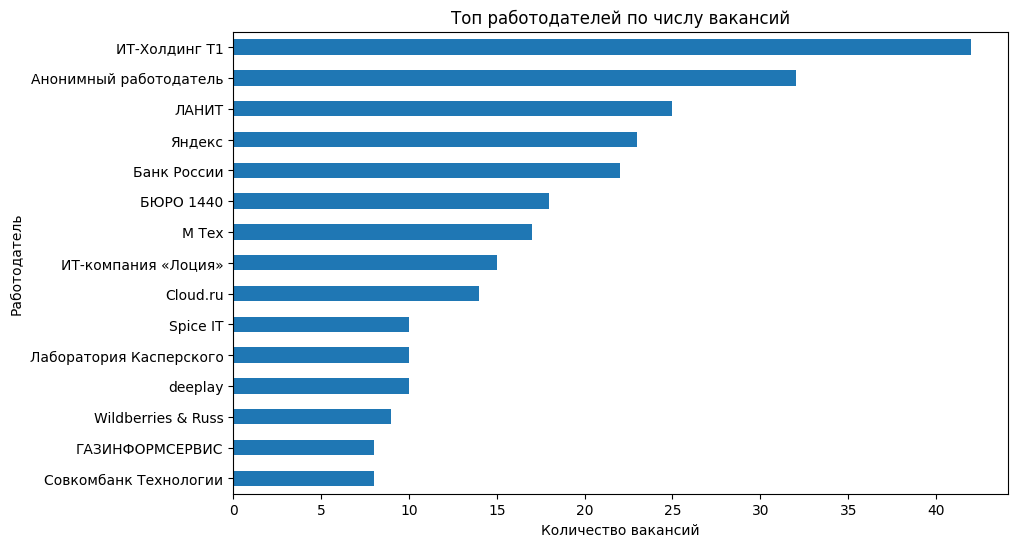

In [24]:
plt.figure(figsize=(10, 6))
top_companies.sort_values().plot(kind="barh")
plt.title("Топ работодателей по числу вакансий")
plt.xlabel("Количество вакансий")
plt.ylabel("Работодатель")
plt.show()

**Вывод:**

Больше всего вакансий в выборке разместил ИТ-Холдинг Т1 — 42 вакансии. Также заметны анонимные работодатели, ЛАНИТ, Яндекс и Банк России.

Какой формат работы предлагается (в офисе / удаленно / ...)?

In [25]:
work_format = df["remote"].map({
    True: "Можно удалённо",
    False: "Только офис",
    None: "Удалёнка не указана"
}).fillna("Удалёнка не указана")

work_format_counts = work_format.value_counts()
work_format_counts

remote
Можно удалённо         276
Удалёнка не указана    239
Name: count, dtype: int64

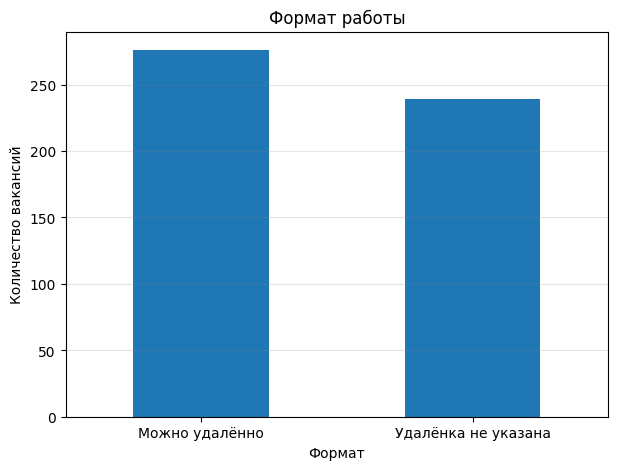

In [26]:
plt.figure(figsize=(7, 5))
work_format_counts.plot(kind="bar")
plt.title("Формат работы")
plt.xlabel("Формат")
plt.ylabel("Количество вакансий")
plt.xticks(rotation=0)
plt.grid(True, axis='y', alpha=0.2, color='gray')
plt.show()

**Вывод:**

В 276 вакансиях явно указана возможность удалённой работы, в 239 вакансиях этого не указано. Так как отсутствие отметки remote=True не обязательно означает строго офисный формат, такие вакансии корректнее рассматривать как "удалёнка не указана".

Исследуйте распределение вакансий по грейдам, сколько вакансий какого грейда представленно в данных?

In [27]:
grade_counts = df["grade"].fillna("Грейд не указан").value_counts()
grade_counts

grade
Senior             155
Middle             135
Грейд не указан    133
Lead                54
Intern              19
Junior              19
Name: count, dtype: int64

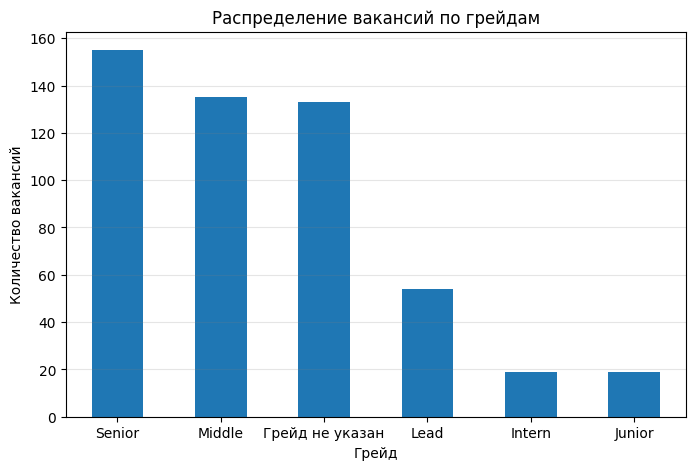

In [28]:
plt.figure(figsize=(8, 5))
grade_counts.plot(kind="bar")
plt.title("Распределение вакансий по грейдам")
plt.xlabel("Грейд")
plt.ylabel("Количество вакансий")
plt.xticks(rotation=0)
plt.grid(True, axis='y', alpha=0.2, color='gray')
plt.show()

**Вывод:**

Больше всего вакансий ориентировано на специалистов уровня Senior и Middle. В 133 вакансиях грейд не указан, поэтому анализ по грейдам нужно воспринимать с осторожностью. Вакансий для Junior и Intern существенно меньше: работодатели чаще ищут специалистов с опытом.

Какую зарплату готовы платить работодатели? Соберите некоторым образом статистику и постройте гистограмму.

При работе с данными о заработной плате обратите внимание на валюту и <a target="_blank" href="https://yandex.ru/search/?text=gross%2Fnet&clid=1955455&win=446&lr=213&noreask=1">gross/net</a>. Постоянно подгружать курс валюты не требуется, достаточно фиксировать какой-то один более менее актуальный.

In [69]:
USD_RATE = 81.1443
EUR_RATE = 93.4247

def parse_salary(text):
    if pd.isna(text):
        return pd.Series([np.nan, np.nan, np.nan, None, None, None])
    
    s = str(text).lower().replace("\xa0", " ")
    is_gross = "gross" in s
    
    if "не указ" in s:
        return pd.Series([np.nan, np.nan, np.nan, None, None, None])
    
    currency = "RUB"
    rate = 1
    
    if "$" in s or "usd" in s or "дол" in s:
        currency = "USD"
        rate = USD_RATE
    elif "€" in s or "eur" in s or "евро" in s:
        currency = "EUR"
        rate = EUR_RATE
    
    nums = re.findall(r"\d[\d ]*", s)
    nums = [float(x.replace(" ", "")) for x in nums]
    
    if len(nums) == 0:
        return pd.Series([np.nan, np.nan, np.nan, currency, None, "gross" if is_gross else "net_or_unknown"])
    
    salary_from = np.nan
    salary_to = np.nan
    
    if "от" in s and "до" in s and len(nums) >= 2:
        salary_from, salary_to = nums[0], nums[1]
        salary_type = "range"
    elif "от" in s:
        salary_from = nums[0]
        salary_type = "from"
    elif "до" in s:
        salary_to = nums[0]
        salary_type = "to"
    elif len(nums) >= 2:
        salary_from, salary_to = nums[0], nums[1]
        salary_type = "range"
    else:
        salary_from = salary_to = nums[0]
        salary_type = "fixed"
    
    salary_from_rub = salary_from * rate if not np.isnan(salary_from) else np.nan
    salary_to_rub = salary_to * rate if not np.isnan(salary_to) else np.nan

    # приводим gross к net
    if is_gross:
        if not np.isnan(salary_from_rub):
            salary_from_rub *= 0.87
        
        if not np.isnan(salary_to_rub):
            salary_to_rub *= 0.87
    
    if not np.isnan(salary_from_rub) and not np.isnan(salary_to_rub):
        salary_mid_rub = (salary_from_rub + salary_to_rub) / 2
    elif not np.isnan(salary_from_rub):
        salary_mid_rub = salary_from_rub
    elif not np.isnan(salary_to_rub):
        salary_mid_rub = salary_to_rub
    else:
        salary_mid_rub = np.nan
    
    return pd.Series([
        salary_from_rub,
        salary_to_rub,
        salary_mid_rub,
        currency,
        salary_type,
        "gross" if is_gross else "net_or_unknown"
    ])

df[["salary_from_rub", "salary_to_rub", "salary_mid_rub", "salary_currency", "salary_type", "salary_tax_type"]] = (
    df["salary_text"].apply(parse_salary)
)

In [70]:
df["salary_tax_type"].value_counts()

salary_tax_type
net_or_unknown    82
Name: count, dtype: int64

В данных не было найдено зарплат, явно указанных как gross. Поэтому численные значения зарплат после нормализации не изменились. Тем не менее обработка gross/net была добавлена: если зарплата указана как gross, она переводится в net с коэффициентом 0.87.

In [71]:
df["salary_mid_rub"].notna().sum()

np.int64(82)

In [72]:
df["salary_currency"].value_counts(dropna=False)

salary_currency
NaN    433
RUB     65
USD     17
Name: count, dtype: int64

In [75]:
salary_stats = df["salary_mid_rub"].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
).round(0)

salary_stats

count        82.0
mean     206075.0
std      140554.0
min       35000.0
10%       66400.0
25%       98030.0
50%      161144.0
75%      318750.0
90%      405149.0
max      689727.0
Name: salary_mid_rub, dtype: float64

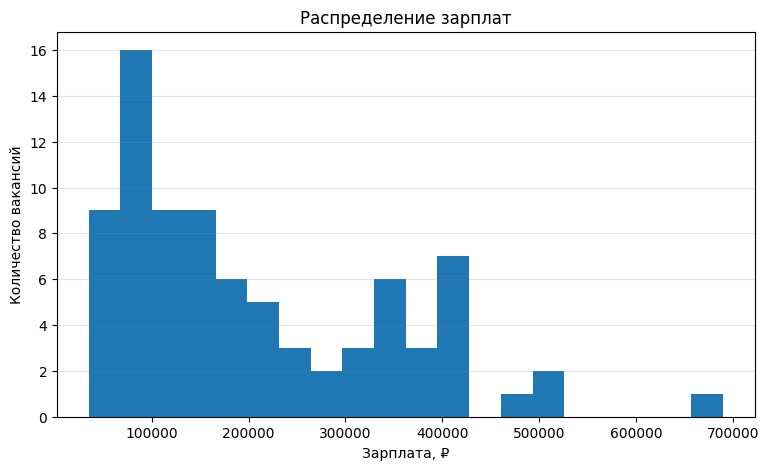

In [76]:
plt.figure(figsize=(9, 5))
df["salary_mid_rub"].dropna().plot(kind="hist", bins=20)
plt.title("Распределение зарплат")
plt.xlabel("Зарплата, ₽")
plt.ylabel("Количество вакансий")
plt.grid(True, axis='y', alpha=0.2, color='gray')
plt.show()

**Вывод:**

Явно указанная зарплата есть только у 82 вакансий из 515. Для анализа все зарплаты были приведены к рублям. Если был указан диапазон «от … до …», использовалась середина диапазона. Если было указано только «от» или только «до», использовалась указанная граница. Медианная зарплата составила около 161 тыс. рублей, средняя — около 206 тыс. рублей. Среднее выше медианы, что говорит о наличии высокооплачиваемых вакансий, смещающих распределение вправо.

Как отличается предлагаемая зарплата в зависимости от грейда?

In [77]:
salary_by_grade = (
    df.dropna(subset=["salary_mid_rub"])
      .groupby("grade")["salary_mid_rub"]
      .agg(["count", "median", "mean", "min", "max"])
      .round(0)
      .sort_values("median")
)

salary_by_grade

,count,median,mean,min,max
grade,,,,,
Intern,9,50000.0,106667.0,35000.0,285000.0
Junior,9,80000.0,77041.0,50000.0,100000.0
Middle,22,151250.0,155852.0,63500.0,344863.0
Senior,22,347432.0,307284.0,100000.0,689727.0
Lead,9,400000.0,373447.0,142003.0,507152.0


<Figure size 800x500 with 0 Axes>

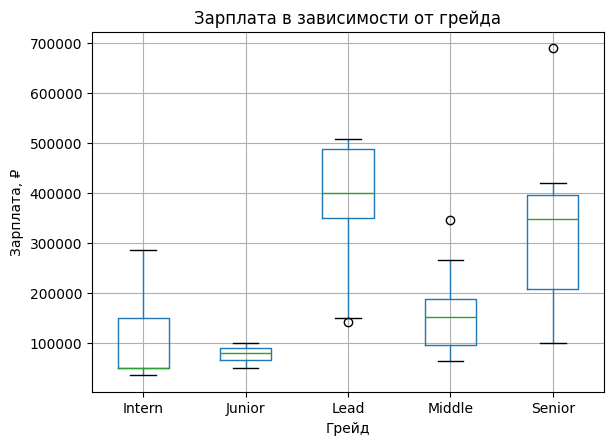

In [78]:
plt.figure(figsize=(8, 5))
df.dropna(subset=["salary_mid_rub", "grade"]).boxplot(
    column="salary_mid_rub",
    by="grade"
)
plt.title("Зарплата в зависимости от грейда")
plt.suptitle("")
plt.xlabel("Грейд")
plt.ylabel("Зарплата, ₽")
plt.show()

**Вывод:**

Зарплата ожидаемо растёт вместе с грейдом. Ширина прямоугольника отражает разброс центральных 50% зарплат, а “усы” показывают диапазон значений без учёта выбросов.

 У Intern и Junior медианные значения самые низкие — около 50 и 80 тыс. рублей. Для Middle медиана составляет около 151 тыс. рублей, для Senior — около 347 тыс. рублей, для Lead — около 400 тыс. рублей. При этом число вакансий с явно указанной зарплатой по каждому грейду небольшое, поэтому выводы нужно считать ориентировочными.

 Для грейда Lead наблюдаются выбросы — отдельные вакансии с существенно более низкой зарплатой относительно основной группы Lead-вакансий. Это может быть связано с различием обязанностей, регионов или особенностями конкретных работодателей.

 Аналогично, для грейда Middle и Senior наблюдаются отдельные вакансии с существенно более высокой зарплатой относительно основной группы.

In [79]:
salary_by_company = (
    df.dropna(subset=["salary_mid_rub"])
      .groupby("company_name")["salary_mid_rub"]
      .agg(["count", "median", "mean"])
      .query("count >= 3")   # убираем компании с 1 вакансией
      .sort_values("median", ascending=False)
      .head(15)
      .round(0)
)

salary_by_company

,count,median,mean
company_name,,,
Яндекс,3,395000.0,351667.0
ITK academy,4,90000.0,89375.0
ИТ-Холдинг Т1,7,90000.0,91643.0
OPENCITY,5,50000.0,50000.0


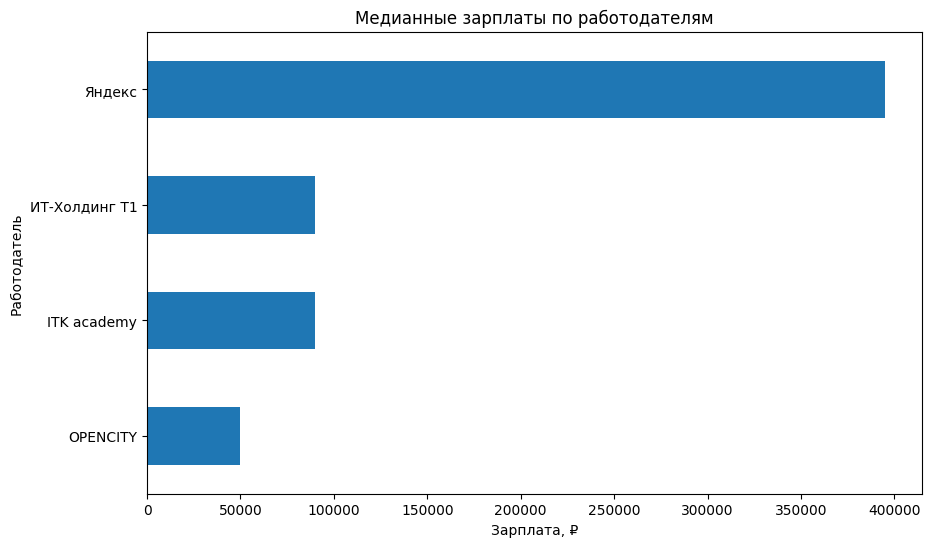

In [80]:
plt.figure(figsize=(10, 6))
salary_by_company.sort_values("median")["median"].plot(
    kind="barh"
)
plt.title("Медианные зарплаты по работодателям")
plt.xlabel("Зарплата, ₽")
plt.ylabel("Работодатель")
plt.show()

**Вывод:** Был проведён анализ зарплат в разрезе работодателей.
Для корректности сравнения были оставлены компании, у которых указано не менее 3 вакансий с зарплатой.
Наиболее высокие медианные зарплаты предлагает компания Яндекс и компании ИТ-Холдинг Т1, ITK academy c большим отрывом от лидера.

Исследуйте географию вакансий. В каких городах и регионах больше всего вакансий?

In [81]:
locations_exploded = df.explode("locations").copy()

locations_exploded["locations"] = locations_exploded["locations"].where(
    locations_exploded["locations"].notna() & (locations_exploded["locations"].astype(str) != ""),
    "Город не указан"
)

top_locations = locations_exploded["locations"].value_counts().head(20)
top_locations

locations
Москва             257
Город не указан    129
Санкт-Петербург     91
Новосибирск         21
Казань              16
Екатеринбург        15
Нижний Новгород     10
Томск                6
Краснодар            6
Хабаровск            5
Самара               5
Владивосток          4
Ижевск               4
Воронеж              3
Пенза                3
Минск                3
Саратов              3
Омск                 3
Йошкар-Ола           2
Коломна              2
Name: count, dtype: int64

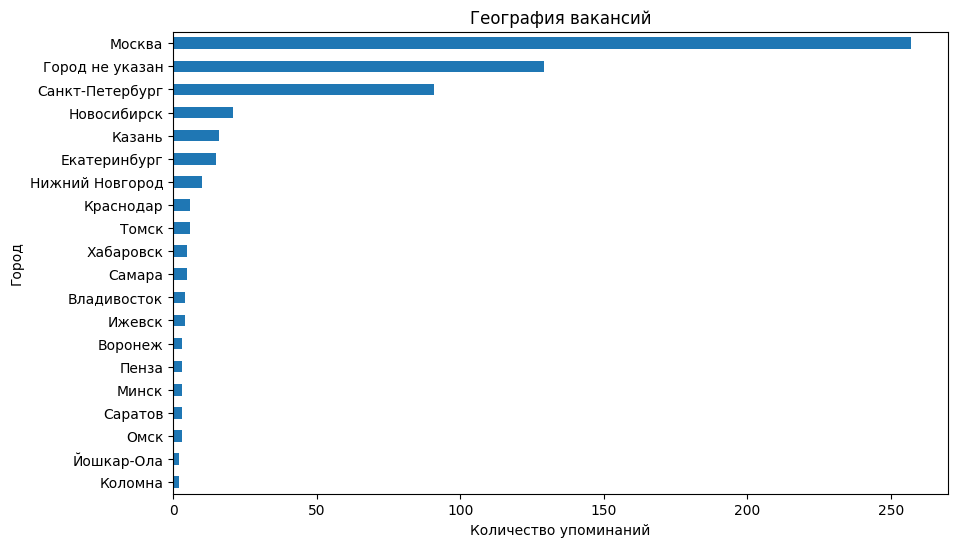

In [82]:
plt.figure(figsize=(10, 6))
top_locations.sort_values().plot(kind="barh")
plt.title("География вакансий")
plt.xlabel("Количество упоминаний")
plt.ylabel("Город")
plt.show()

**Вывод:**

Основная часть вакансий сосредоточена в Москве и Санкт-Петербурге. Москва встречается 257 раз, Санкт-Петербург — 91 раз. Также заметны Новосибирск, Казань, Екатеринбург и Нижний Новгород. При этом у 129 вакансий город не указан, что частично связано с удалённым форматом работы.

Какие выводы можно сделать на основе проведенного анализа?

**Выводы:**

В выборке содержится 515 вакансий Career.Habr за период с 30 марта по 28 апреля 2026 года. Дубликатов по идентификатору вакансии и URL нет.

Наибольшее количество вакансий разместили крупные IT-работодатели: ИТ-Холдинг Т1, ЛАНИТ, Яндекс, Банк России, БЮРО 1440. Значительная часть вакансий допускает удалённую работу: такая возможность явно указана в 276 вакансиях.

По грейдам преобладают вакансии для Senior и Middle-специалистов. Junior и Intern-вакансий значительно меньше, что показывает более высокий спрос на опытных кандидатов.

Зарплата явно указана только в 82 вакансиях, поэтому зарплатный анализ основан на ограниченной подвыборке. Зарплаты были приведены к рублям, а диапазоны обработаны через среднее значение между нижней и верхней границей. Медианная зарплата составила около 161 тыс. рублей, средняя — около 206 тыс. рублей. Зарплата растёт вместе с грейдом: от Junior/Intern к Middle, Senior и Lead.

Географически вакансии в основном сконцентрированы в Москве и Санкт-Петербурге, однако большое число вакансий допускает удалёнку или не содержит конкретного города. Это говорит о том, что рынок IT-вакансий не так жёстко привязан к региону.

#### 3. Навыки и инструменты

Исследуем, какие навыки чаще всего востребованы в представленных вакансиях.

Найдите поле в данных, соответствующее навыкам, проанализируйте его и составьте список навыков и количество упоминаний каждого.

In [83]:
df["skills"].head()

0                         [Deep Learning, SQL, Python]
1                                        [SQL, Python]
2         [SQL, Python, PostgreSQL, BI, Анализ данных]
3    [SQL, Python, NLP, Большие данные, Базы данных...
4    [Apache Spark, Git, Jira, SQL, Python, Машинно...
Name: skills, dtype: object

In [84]:
# наиболее частые навыки
skills_counter = Counter()

for skills_list in df["skills"]:
    if isinstance(skills_list, list):
        skills_counter.update(skills_list)

top_skills = pd.DataFrame(
    skills_counter.most_common(30),
    columns=["skill", "count"]
)

top_skills

,skill,count
0,SQL,114
1,Python,105
2,Linux,85
3,PostgreSQL,65
4,Docker,44
5,Java,38
6,Kubernetes,34
7,BPMN,31
8,C++,31
9,Базы данных,29


<Figure size 1200x1400 with 0 Axes>

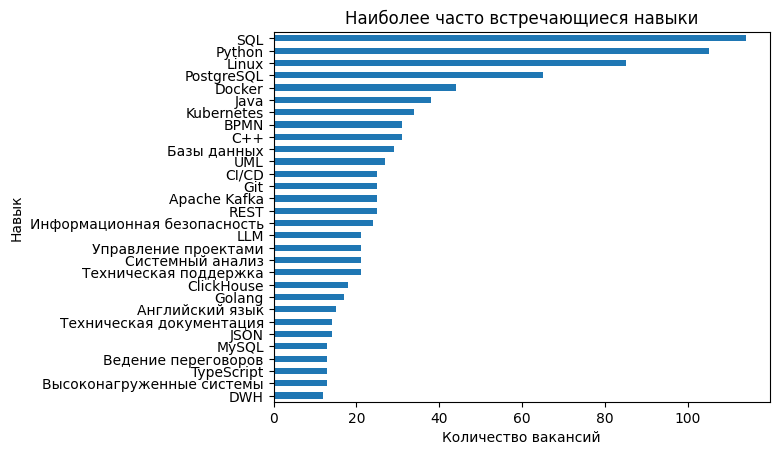

In [85]:
plt.figure(figsize=(12, 14))

top_skills.sort_values("count").plot(
    x="skill",
    y="count",
    kind="barh",
    legend=False
)

plt.title("Наиболее часто встречающиеся навыки")
plt.xlabel("Количество вакансий")
plt.ylabel("Навык")
plt.show()

В данных присутствует отдельное поле skills, содержащее список навыков для вакансии. Анализ этого поля показывает, что чаще всего встречаются Python, SQL, Git, PostgreSQL, Docker, Linux и машинное обучение.

Однако это поле содержит далеко не полный набор требований. Во многих вакансиях описание содержит значительно больше информации о необходимых знаниях и технологиях, чем перечислено в skills. Например, в тексте вакансий встречаются упоминания:
- NLP,
- рекомендательных систем,
- градиентного бустинга,
- статистики,
- временных рядов,
- A/B-тестов,
- CatBoost,
- XGBoost,
- LightGBM,
- feature engineering,
- ranking,
- трансформеров,
- линейной алгебры,
- проверки гипотез,
хотя в поле skills эти навыки отсутствуют.

Поэтому для более полного анализа необходимо извлекать навыки непосредственно из текстового описания вакансий.

Однако, в этом списке навыков могут быть указаны не все необходимые навыки. Посмотрите на текстовое описание некоторых вакансий. В нем можно встретить перечисление гораздо большего количества требуемых навыков. Вот только несколько примеров из выданных данных: 

> 1. **Вакансия №4**
>
>     В описании: "*ML-research в области NLP, анализа графов и нейронных сетей.*"
> 
>     В поле навыков: `['Apache Spark', 'Git', 'Jira', 'SQL', 'Python', 'Машинное обучение']`<br/><br/>
> 
> 2. **Вакансия №5**
>
>     В описании: "*Глубокое знание классических алгоритмов машинного обучения и математической статистики*"
> 
>     В поле навыков: `['Python', 'SQL', 'Apache Kafka']`<br/><br/>
> 
> 3. **Вакансия №6**
>
>     В описании: "*Глубокое понимание классического машинного обучения: линейные модели, деревья решений, ансамбли, кластеризация, feature engineering. Опыт разработки рекомендательных систем: матричная факторизация, контентные и коллаборативные подходы, трансформеры, двухэтапные архитектуры (retrieval + ranking). Уверенный опыт работы с градиентным бустингом (CatBoost, LightGBM, XGBoost) и пониманием их внутренних механизмов. Опыт работы с временными рядами. Знание теории вероятности, математической статистики и линейной алгебры в прикладном контексте. Умение проверять статистические гипотезы, работать с доверительными интервалами, оценивать значимость признаков. Понимание принципов валидации моделей на временных данных, борьбы с data leakage и переобучением. Знание методов ранжирования, метрик ранжирования (NDCG, MRR, MAP) и метрик оценки рекомендательных систем (HitRate@K, Recall@K, Coverage, Diversity). Уверенное знание Python на уровне ООП (+ классический набор библиотек: pandas, numpy, scikit-learn, matplotlib/seaborn/plotly). Опыт проведения A/B-тестов и дизайна экспериментов для оценки эффективности моделей*"
> 
>     В поле навыков: `['Машинное обучение']`<br/><br/>


Такая ситуация нас, конечно, не устраивает. Ведь в первую очередь вам сейчас было бы полезно понять, какие вузовские предметы для вас наиболее актуальны, по каким направлениям стоит подтянуть свои знания и навыки.

Задача &mdash; вытянуть из полных описаний вакансий достаточно полный список навыков. Навыки должны быть достаточно общими, например, в качестве навыка может быть "задача обучения ранжированию" (характеризует область DS), но не "метрика NDCG для ранжирования" (конкретное понятие в ранжировании). Тем не менее, степень детализации навыков вы можете выбрать самостоятельно исходя из своих профессиональных интересов. Также стоит разделить навыки на методологические (математика, методы, модели, алгоритмы и т.д.) и инструментальные (Python, библиотеки, Spark и т.д.).

Для решения этой задачи можно использовать ИИ без ограничений, но нужно понимать и проверять решение, которое он предлагает. Напомним, что ссылку на чат с ИИ необходимо прикрепить к работе, при этом работа все еще является индивидуальной, при обнаружении списывания все участники получат 0 за задание и штраф к итоговой оценке за курс.

Опишите методику решения задачи

##### Для извлечения навыков использовался словарный подход

Был сформирован набор ключевых навыков и технологий, после чего для каждой вакансии производился поиск упоминаний этих навыков в поле description_text.

Навыки были разделены на два типа:
1. Методологические навыки:
- математическая статистика,
- машинное обучение,
- NLP,
- рекомендательные системы,
- A/B-тестирование,
- временные ряды,
- feature engineering,
- deep learning,
- ranking,
- кластеризация,
- ансамбли,
- градиентный бустинг,
- теория вероятностей,
- линейная алгебра и др.

2. Инструментальные навыки:
- Python,
- SQL,
- Spark,
- Docker,
- Kubernetes,
- Airflow,
- Kafka,
- Pandas,
- NumPy,
- PyTorch,
- TensorFlow,
- CatBoost,
- XGBoost,
- LightGBM,
- Git,
- Linux и др.

Для поиска использовалось приведение текста к нижнему регистру и поиск ключевых слов по подстроке. Такой подход не требует обучения модели и хорошо подходит для задач извлечения профессиональных навыков из технических вакансий.

Теперь приведите реализацию решения

In [86]:
methodological_skills = {
    "машинное обучение": [
        "машинн", "machine learning", "ml"
    ],
    
    "deep learning": [
        "deep learning", "глубок", "нейронн"
    ],
    
    "nlp": [
        "nlp", "natural language processing"
    ],
    
    "рекомендательные системы": [
        "рекомендатель", "recommendation"
    ],
    
    "временные ряды": [
        "временн", "time series"
    ],
    
    "a/b тестирование": [
        "a/b", "ab-тест", "ab test"
    ],
    
    "математическая статистика": [
        "статистик"
    ],
    
    "теория вероятностей": [
        "теория вероят", "probability"
    ],
    
    "линейная алгебра": [
        "линейн"
    ],
    
    "feature engineering": [
        "feature engineering"
    ],
    
    "градиентный бустинг": [
        "boosting", "catboost", "xgboost", "lightgbm"
    ],
    
    "кластеризация": [
        "кластеризац", "clustering"
    ],
    
    "ранжирование": [
        "ranking", "ранжир"
    ],
    
    "computer vision": [
        "computer vision", "cv"
    ]
}

instrumental_skills = {
    "python": ["python"],
    "sql": ["sql"],
    "git": ["git"],
    "linux": ["linux"],
    "docker": ["docker"],
    "kubernetes": ["kubernetes", "k8s"],
    "spark": ["spark"],
    "airflow": ["airflow"],
    "kafka": ["kafka"],
    "pandas": ["pandas"],
    "numpy": ["numpy"],
    "scikit-learn": ["scikit", "sklearn"],
    "pytorch": ["pytorch"],
    "tensorflow": ["tensorflow"],
    "catboost": ["catboost"],
    "xgboost": ["xgboost"],
    "lightgbm": ["lightgbm"],
    "postgresql": ["postgres"],
    "clickhouse": ["clickhouse"],
    "redis": ["redis"]
}

def extract_skills(text, skills_dict):
    if pd.isna(text):
        return []
    
    text = text.lower()
    found = []
    
    for skill, patterns in skills_dict.items():
        for pattern in patterns:
            if pattern in text:
                found.append(skill)
                break
    
    return found

df["methodological_extracted"] = df["description_text"].apply(
    lambda x: extract_skills(x, methodological_skills)
)

df["instrumental_extracted"] = df["description_text"].apply(
    lambda x: extract_skills(x, instrumental_skills)
)

Отлично, у нас есть полноценный набор навыков для каждой вакансии. Теперь еще раз посмотрите, какие навыки каждого типа (методологические и инструментальные) наиболее востребованы.

In [87]:
method_counter = Counter()

for skills in df["methodological_extracted"]:
    method_counter.update(skills)

method_df = pd.DataFrame(
    method_counter.most_common(),
    columns=["skill", "count"]
)

method_df

,skill,count
0,временные ряды,203
1,машинное обучение,147
2,deep learning,93
3,математическая статистика,27
4,a/b тестирование,19
5,computer vision,12
6,nlp,11
7,кластеризация,8
8,ранжирование,5
9,линейная алгебра,4


<Figure size 1000x700 with 0 Axes>

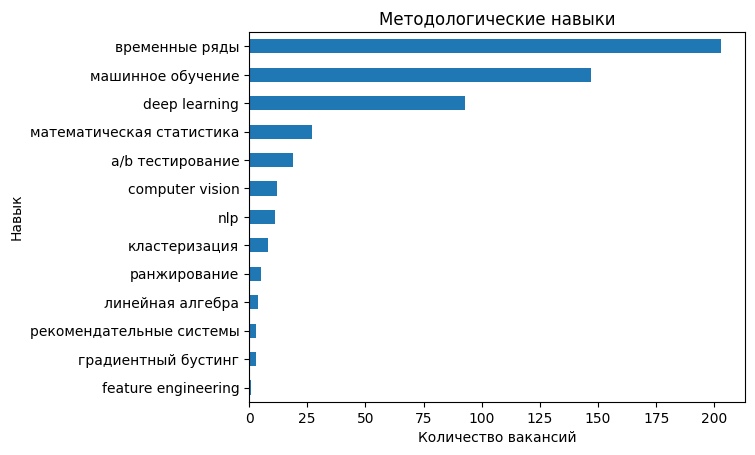

In [88]:
plt.figure(figsize=(10, 7))

method_df.sort_values("count").plot(
    x="skill",
    y="count",
    kind="barh",
    legend=False
)

plt.title("Методологические навыки")
plt.xlabel("Количество вакансий")
plt.ylabel("Навык")
plt.show()

In [89]:
instr_counter = Counter()

for skills in df["instrumental_extracted"]:
    instr_counter.update(skills)

instr_df = pd.DataFrame(
    instr_counter.most_common(),
    columns=["skill", "count"]
)

instr_df

,skill,count
0,sql,206
1,python,157
2,git,140
3,linux,130
4,docker,105
5,postgresql,96
6,kubernetes,81
7,kafka,64
8,clickhouse,39
9,redis,37


<Figure size 1000x800 with 0 Axes>

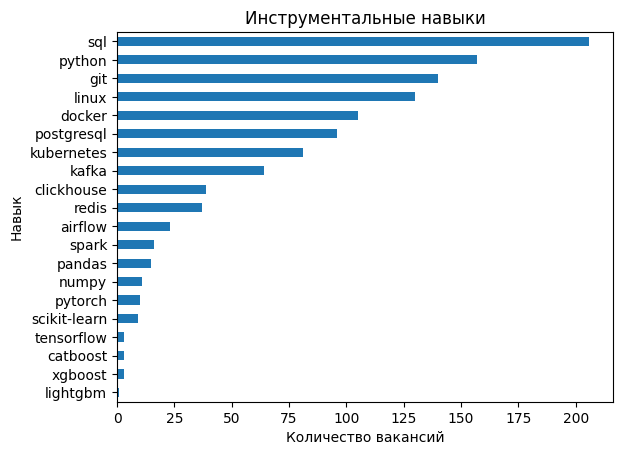

In [90]:
plt.figure(figsize=(10, 8))

instr_df.sort_values("count").plot(
    x="skill",
    y="count",
    kind="barh",
    legend=False
)

plt.title("Инструментальные навыки")
plt.xlabel("Количество вакансий")
plt.ylabel("Навык")
plt.show()

Выводы:

Анализ текстовых описаний вакансий позволил извлечь значительно более полный набор навыков, чем содержится в поле skills.

Среди методологических навыков наиболее востребованы:
- временные ряды,
- машинное обучение,
- deep learning,
- математическая статистика,
- A/B-тестирование,
- computer vision,
- NLP,
- кластеризация,
- ранжирование.

Особенно часто в описаниях вакансий встречаются задачи анализа временных рядов и машинного обучения. Это говорит о высоком спросе на специалистов, умеющих работать с прогнозированием, ML-моделями и анализом данных.

Среди инструментальных навыков чаще всего встречаются:
- SQL,
- Python,
- Git,
- Linux,
Spark,
- Docker,
- PostgreSQL,
- Kubernetes,
- Kafka,
- ClickHouse,
- Redis.

Также заметен спрос на инструменты обработки данных и ML-библиотеки:
- Airflow,
- Spark,
- Pandas,
- NumPy,
- PyTorch,
- scikit-learn.

Анализ показывает, что работодатели ожидают от специалистов не только знания инструментов разработки, но и глубокого понимания математических и алгоритмических основ Data Science и Machine Learning.

Особенно востребованы:
- машинное обучение;
- обработка временных рядов;
- distributed/data infrastructure;
- контейнеризация и orchestration;
- работа с базами данных;
- обработка потоковых данных.

Это означает, что при подготовке к работе в сфере Data Science, ML и backend-разработки особенно важно уделять внимание:
- математической статистике;
- машинному обучению;
- Python + знанию библиотек;
- SQL и базам данных;
- Linux и DevOps-инструментам;
- распределённым системам и обработке данных.


#### 4.   Зарплата

Проверьте, во скольких вакансиях среди выгруженных указана зарплата?


Ответ: Зарплата указана в 82 вакансиях среди всех выгруженных.

In [91]:
df["salary_mid_rub"].notna().sum()

np.int64(82)

In [92]:
salary_known = df["salary_mid_rub"].notna().sum()
salary_unknown = df["salary_mid_rub"].isna().sum()

print("Известна зарплата:", salary_known)
print("Не указана зарплата:", salary_unknown)

print(
    "Доля вакансий с зарплатой:",
    round(salary_known / len(df) * 100, 2),
    "%"
)

Известна зарплата: 82
Не указана зарплата: 433
Доля вакансий с зарплатой: 15.92 %


**Вывод:** Среди 515 вакансий зарплата явно указана только в 82 вакансиях (около 16%). Для остальных вакансий зарплата отсутствует, поэтому возникает задача оценки ожидаемой заработной платы на основе текстового описания вакансии.

На основе описания вакансий с известной зарплатой попробуйте оценить ожидаемую зарплату для всех остальных вакансий. Для этого на основе текстового описания вакансии можно построить эмбеддинги (любые подходящие нейросетевые или просто one-hot кодирование). По этим эмбеддингам обучите некоторую модель предсказывать зарплату. 

Не забудьте по общий пайплайн ML-моделей, а также про применимость различных методов.

In [93]:
ml_df = df.dropna(subset=["salary_mid_rub"]).copy()

X = ml_df["description_text"]
y = ml_df["salary_mid_rub"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [94]:
baseline_pred = np.full_like(
    y_test,
    y_train.median(),
    dtype=float
)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline MAE:", round(baseline_mae))
print("Baseline RMSE:", round(baseline_rmse))
print("Baseline R2:", round(baseline_r2, 3))

Baseline MAE: 118569
Baseline RMSE: 159122
Baseline R2: -0.265


In [95]:
model = Ridge(alpha=1.0)
model.fit(X_train_vec, y_train)

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [96]:
preds = model.predict(X_test_vec)

mae = mean_absolute_error(y_test, preds)
rmse = np.sqrt(mean_squared_error(y_test, preds))
r2 = r2_score(y_test, preds)

print("MAE:", round(mae))
print("RMSE:", round(rmse))
print("R2:", round(r2, 3))

MAE: 100131
RMSE: 126152
R2: 0.205


In [97]:
print("\nСравнение:")
print("Baseline MAE:", round(baseline_mae))
print("Ridge MAE:", round(mae))


Сравнение:
Baseline MAE: 118569
Ridge MAE: 100131


**Вывод:** 

Модель Ridge показала MAE 100 131 ₽ против 118 569 ₽ у baseline-модели. Это означает, что модель даёт более точные предсказания, чем простое предсказание медианной зарплатой.

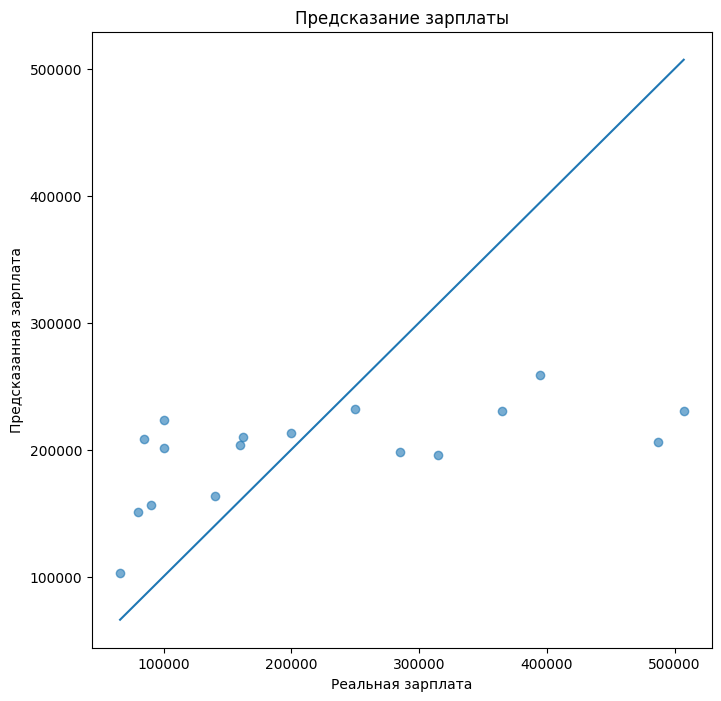

In [98]:
plt.figure(figsize=(8, 8))
plt.scatter(y_test, preds, alpha=0.6)
plt.xlabel("Реальная зарплата")
plt.ylabel("Предсказанная зарплата")
plt.title("Предсказание зарплаты")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.show()

In [99]:
unknown_salary_df = df[df["salary_mid_rub"].isna()].copy()

X_unknown = vectorizer.transform(
    unknown_salary_df["description_text"]
)

predicted_salary = model.predict(X_unknown)
unknown_salary_df["predicted_salary"] = predicted_salary

unknown_salary_df[
    ["title", "company_name", "predicted_salary"]
].head(10)

,title,company_name,predicted_salary
0,Data Scientist,Фарпост,223763.752453
1,Data Scientist,М Тех,215076.068487
4,Data Scientist Middle/Senior Scoring,beeline,199816.107512
5,Data Scientist,М Тех,217405.951880
6,Data Scientist RecSys,SimbirSoft,212503.256682
7,Data Engineer,Т-Банк,213854.715785
8,Data analyst,ИТ-компания «Лоция»,216844.620812
9,Data Engineer,Coral Club,200459.512199
11,Data Engineer,CINIMEX,204307.957841
12,Data Engineer mid (DWH),СберЗдоровье,197461.557457


In [100]:
unknown_salary_df["predicted_salary"].describe().round(0)

count       433.0
mean     207911.0
std       19947.0
min      143248.0
25%      196056.0
50%      206133.0
75%      217835.0
max      285239.0
Name: predicted_salary, dtype: float64

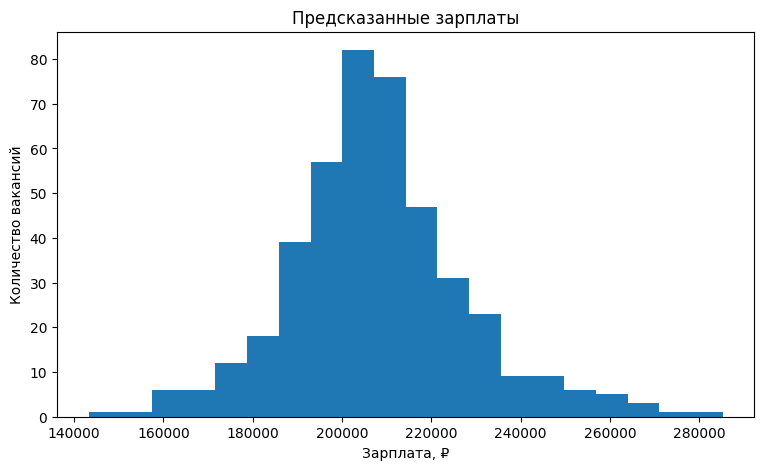

In [101]:
plt.figure(figsize=(9, 5))

unknown_salary_df["predicted_salary"].plot(
    kind="hist",
    bins=20
)

plt.title("Предсказанные зарплаты")
plt.xlabel("Зарплата, ₽")
plt.ylabel("Количество вакансий")
plt.show()

Какие выводы можно сделать?

##### Выводы

- Зарплата явно указана только у небольшой части вакансий — 82 из 515 (15.92%). Для остальных вакансий зарплата отсутствует, поэтому была поставлена задача предсказания зарплаты по текстовому описанию вакансии.

- Для решения задачи использовался классический NLP pipeline:
  - TF-IDF-векторизация текста;
  - Ridge Regression.

- Такой подход хорошо подходит для небольших датасетов и разреженных текстовых признаков.

- Модель показала умеренное качество:
  - MAE составила около 100 тыс. рублей;
  - RMSE — около 126 тыс. рублей;
  - R² = 0.205.

- Положительное значение R² показывает, что текст вакансии действительно содержит информацию, связанную с уровнем предлагаемой зарплаты. Однако качество модели остаётся ограниченным.

- На графике предсказаний видно, что модель плохо предсказывает экстремальные значения зарплат:
  - высокие зарплаты обычно занижаются;
  - низкие зарплаты часто завышаются.

- Большинство предсказанных зарплат лежит в диапазоне 180–240 тыс. рублей. Это говорит о том, что модель склонна предсказывать значения около среднего уровня зарплат.

- Для вакансий без указанной зарплаты модель предсказала:
  - среднюю зарплату около 208 тыс. рублей;
  - медианную зарплату около 206 тыс. рублей.

- Основные ограничения модели:
  - небольшой объём обучающей выборки;
  - только 82 вакансии с известной зарплатой;
  - шумность текстовых описаний;
  - отсутствие важных признаков (регион, компания, опыт, стек технологий);
  - использование простой линейной модели.

- Для улучшения качества модели можно:
  - увеличить объём данных;
  - использовать более сложные эмбеддинги (например, sentence-transformers);
  - добавить структурные признаки;
  - использовать CatBoost или нейросетевые модели.

#### 5. Кластеризация

Теперь выполним кластеризацию вакансий. В качестве признаков можете использовать различную информацию, например, навыки и эмбеддинги. Перед выполнением кластеризации стоит подумать над целями &mdash; что вы хотите от кластеризации? Разделить вакансии по навыкам? Или, может быть, кластеризовать вакансии по условиям работы?

Распишите цели кластеризации и методику подготовки признаков

Цель кластеризации — разделить вакансии на группы по смысловой близости: похожим требованиям, навыкам, технологиям и описанию задач.

В этом пункте кластеризация используется не для предсказания зарплаты, а для исследования структуры рынка вакансий. Хотим понять, какие типы вакансий присутствуют в данных: например, backend-разработка, data science / machine learning, аналитика, DevOps / infrastructure и управленческие позиции.

В качестве признаков используются:
- текстовое описание вакансии description_text;
- название вакансии title;
- специализация specialization;
- навыки из поля skills;
- извлечённые ранее методологические и инструментальные навыки.

ак как большинство признаков являются текстовыми, для кластеризации необходимо сначала преобразовать их в числовой вид. Для этого используется TF-IDF-векторизация. Затем применяется KMeans.

Выполните кластеризаци подробно проинтерпретируйте кластеры.

In [102]:
def list_to_text(x):
    if isinstance(x, list):
        return " ".join(map(str, x))
    return "" if pd.isna(x) else str(x)

In [103]:
df["skills_text"] = df["skills"].apply(list_to_text)

df["methodological_text"] = df["methodological_extracted"].apply(list_to_text)
df["instrumental_text"] = df["instrumental_extracted"].apply(list_to_text)

df["cluster_text"] = (
    df["title"].fillna("") + " " +
    df["specialization"].fillna("") + " " +
    df["skills_text"].fillna("") + " " +
    df["methodological_text"].fillna("") + " " +
    df["instrumental_text"].fillna("") + " " +
    df["description_text"].fillna("")
)

In [104]:
vectorizer_cluster = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.85
)

X_cluster = vectorizer_cluster.fit_transform(df["cluster_text"])
X_cluster.shape

(515, 3000)

In [105]:
inertias = []
silhouettes = []

cluster_range = range(2, 11)

for k in cluster_range:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = model.fit_predict(X_cluster)
    
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_cluster, labels))

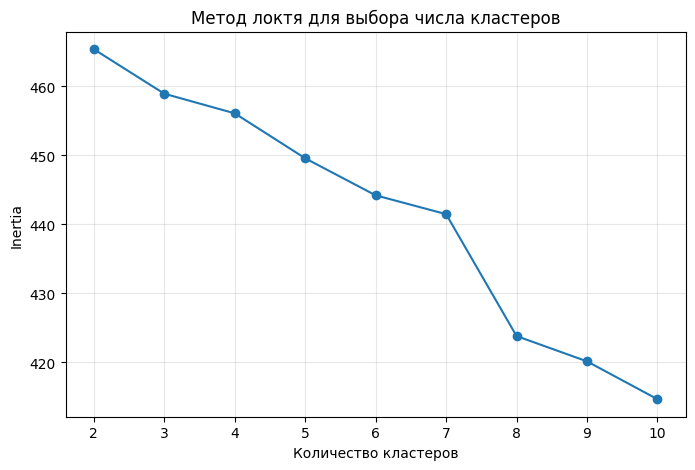

In [106]:
plt.figure(figsize=(8, 5))
plt.plot(list(cluster_range), inertias, marker="o")
plt.title("Метод локтя для выбора числа кластеров")
plt.xlabel("Количество кластеров")
plt.ylabel("Inertia")
plt.grid(alpha=0.3)
plt.show()

Для выбора количества кластеров использовался метод локтя. Идея метода состоит в анализе значения inertia — суммы квадратов расстояний объектов до центров своих кластеров.
При увеличении числа кластеров inertia уменьшается, однако после некоторого момента улучшение становится значительно менее заметным. Эта точка и называется «локтем».

По графику видно, что после 5 кластеров уменьшение inertia становится менее существенным, поэтому было выбрано значение k = 5.

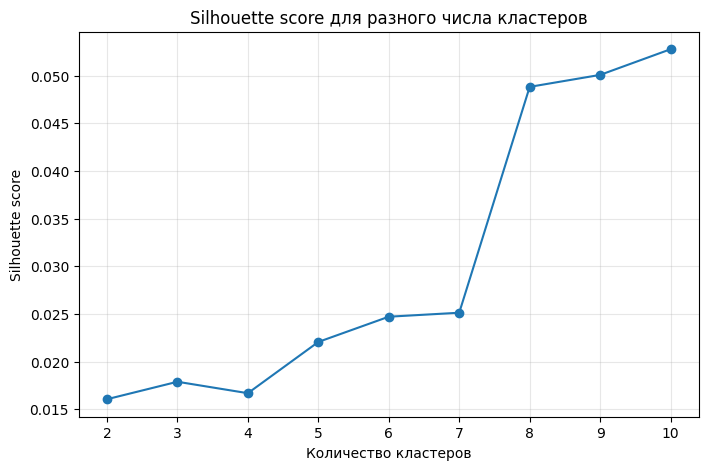

In [107]:
plt.figure(figsize=(8, 5))
plt.plot(list(cluster_range), silhouettes, marker="o")
plt.title("Silhouette score для разного числа кластеров")
plt.xlabel("Количество кластеров")
plt.ylabel("Silhouette score")
plt.grid(alpha=0.3)
plt.show()

Дополнительно использовался silhouette score — метрика качества кластеризации. Она показывает, насколько объекты внутри одного кластера похожи друг на друга и насколько хорошо кластеры отделены между собой. Чем выше silhouette score, тем лучше разделение кластеров.

In [108]:
N_CLUSTERS = 5

kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=42,
    n_init="auto"
)

df["cluster"] = kmeans.fit_predict(X_cluster)
df["cluster"].value_counts().sort_index()

cluster
0     25
1     34
2    133
3    164
4    159
Name: count, dtype: int64

In [109]:
pca = PCA(n_components=2, random_state=42)

X_dense = X_cluster.toarray()
X_pca = pca.fit_transform(X_dense)

df["pca_1"] = X_pca[:, 0]
df["pca_2"] = X_pca[:, 1]

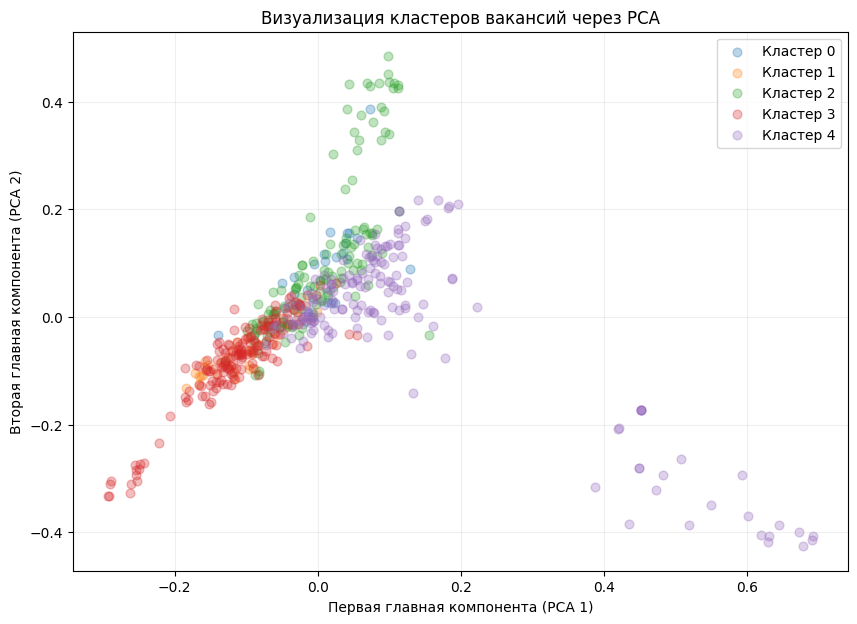

In [110]:
plt.figure(figsize=(10, 7))

for cluster in sorted(df["cluster"].unique()):
    part = df[df["cluster"] == cluster]
    plt.scatter(
        part["pca_1"],
        part["pca_2"],
        label=f"Кластер {cluster}",
        alpha=0.3,
        s=40
    )

plt.title("Визуализация кластеров вакансий через PCA")
plt.xlabel("Первая главная компонента (PCA 1)")
plt.ylabel("Вторая главная компонента (PCA 2)")
plt.grid(alpha=0.2)
plt.legend()
plt.show()

In [111]:
terms = vectorizer_cluster.get_feature_names_out()
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

for cluster_id in range(N_CLUSTERS):
    print(f"\nКластер {cluster_id}")
    print("-" * 40)
    
    top_terms = [terms[ind] for ind in order_centroids[cluster_id, :20]]
    print(", ".join(top_terms))


Кластер 0
----------------------------------------
and, шаг космос, мечтает быть, компании шаг, этому причастным, покорения космоса, покорения, причастным, космоса, космоса мечтает, кто вдохновлен, космос, мечтает, быть этому, вдохновлен, вдохновлен идеей, идеей покорения, шаг, космос для, испытаний

Кластер 1
----------------------------------------
вы, имеете, умеете, яндекса, мы, понимаете, яндексе, имеете опыт, ml, python, данных, есть, вам, wildberries, russ, llm, сотрудников, знаете, программы, как

Кластер 2
----------------------------------------
1с, данных, sql, бизнес, аналитик, опыт работы, требований, знание, системный, мы, процессов, анализ, разработки, python, 00, компании, postgresql, обучение, или, системный аналитик

Кластер 3
----------------------------------------
ai, мы, не, docker, python, ты, опыт работы, что, kubernetes, понимание, или, git, sql, ci, ml, работать, api, за, компании, продукта

Кластер 4
----------------------------------------
т1, linux, безопа

In [112]:
for cluster_id in range(N_CLUSTERS):
    print(f"\nКластер {cluster_id}")
    print("-" * 80)
    
    display(
        df[df["cluster"] == cluster_id][
            ["title", "company_name", "grade", "specialization", "salary_mid_rub"]
        ].head(10)
    )


Кластер 0
--------------------------------------------------------------------------------


,title,company_name,grade,specialization,salary_mid_rub
33,Аналитик DWH,БЮРО 1440,Senior,Системный аналитик,NaN
38,PPC Manager (Yandex Direct),Freuders,Senior,Контекстолог,405721.50
100,Системный аналитик,БЮРО 1440,NaN,Инженер по данным,NaN
123,Программист-математик,БЮРО 1440,Senior,Разработчик приложений,NaN
186,Ведущий разработчик машинного обучения,БЮРО 1440,Lead,ML разработчик,NaN
192,Senior Computer Vision Engineer,Анонимный работодатель,Senior,Инженер по компьютерному зрению,NaN
214,Системный инженер - стажёр (направление радиот...,БЮРО 1440,Intern,Системный инженер,NaN
225,General QA,IT Consult,Middle,Инженер по автоматизации тестирования,137945.31
242,Старший системный аналитик (разработка инженер...,БЮРО 1440,Senior,Системный аналитик,NaN
279,Системный аналитик (Единые системы управления),БЮРО 1440,Senior,Системный аналитик,NaN



Кластер 1
--------------------------------------------------------------------------------


,title,company_name,grade,specialization,salary_mid_rub
20,Java developer (Data platform / BigData),Arenadata,Senior,Бэкенд разработчик,NaN
24,Руководитель группы разработки в Data center i...,Яндекс,Lead,Бэкенд разработчик,NaN
28,Product Analyst,Wildberries & Russ,Senior,Продуктовый аналитик,NaN
46,Продуктовый аналитик в Путешествия,Яндекс,Senior,Продуктовый аналитик,NaN
55,NLP-разработчик в Алису,Яндекс,NaN,ML разработчик,NaN
58,IOS-разработчик в Маркетплейс,Wildberries & Russ,Senior,Разработчик мобильных приложений,NaN
62,Product Marketing Manager / Продуктовый маркет...,Assistance Group,Middle,Продуктовый маркетолог,NaN
77,Ведущий разработчик / техлид WebRTC,Яндекс,Lead,Бэкенд разработчик,NaN
82,Ведущий операционный менеджер в сервис BareMetal,Яндекс,NaN,Инженер ЦОД,NaN
87,Аналитик данных (Внутренний контроль),Wildberries & Russ,Senior,Аналитик по данным,NaN



Кластер 2
--------------------------------------------------------------------------------


,title,company_name,grade,specialization,salary_mid_rub
2,Data Analyst / Data Scientist (Fintech / Payme...,AUROSPACE Holding,Senior,Аналитик по данным,365149.35
3,Data Scientist Senior (Part-time),Strikt,Senior,Ученый по данным,300000.00
7,Data Engineer,Т-Банк,Middle,Инженер по данным,NaN
8,Data analyst,ИТ-компания «Лоция»,NaN,Аналитик по данным,NaN
9,Data Engineer,Coral Club,Middle,Инженер по данным,NaN
11,Data Engineer,CINIMEX,Middle,Инженер по данным,NaN
12,Data Engineer mid (DWH),СберЗдоровье,Middle,Инженер по данным,NaN
13,Data Steward/Менеджер по данным,АстраЗенека,Middle,Инженер по данным,NaN
14,Аналитик данных (Senior Data Analyst),ЛАНИТ,Senior,Аналитик по данным,NaN
17,Data Engineer (разработчик DWH),X5 Tech,NaN,Инженер по данным,NaN



Кластер 3
--------------------------------------------------------------------------------


,title,company_name,grade,specialization,salary_mid_rub
0,Data Scientist,Фарпост,Middle,Ученый по данным,NaN
1,Data Scientist,М Тех,Senior,Ученый по данным,NaN
4,Data Scientist Middle/Senior Scoring,beeline,Middle,Ученый по данным,NaN
5,Data Scientist,М Тех,Senior,Ученый по данным,NaN
6,Data Scientist RecSys,SimbirSoft,NaN,Ученый по данным,NaN
10,Data-engineer,OPENCITY,Intern,Инженер по данным,50000.0
15,Data engineer / архитектор хранилища данных,Торглайн,Senior,Архитектор баз данных,NaN
16,Data Engineer [Middle],deeplay,NaN,Инженер по данным,NaN
18,Аккаунт-директор / Account Director (e-commerc...,AЭРО,Middle,Директор по работе с клиентами,NaN
23,iOS-разработчик,М Тех,NaN,Разработчик мобильных приложений,NaN



Кластер 4
--------------------------------------------------------------------------------


,title,company_name,grade,specialization,salary_mid_rub
42,Java разработчик (СОПББ),ИТ-Холдинг Т1,Senior,Бэкенд разработчик,NaN
60,Начальник отдела автотестирования,Банк России,Lead,Менеджер по обеспечению качества,NaN
61,SDET QA инженер (Java auto),Банк России,Middle,Инженер по автоматизации тестирования,NaN
64,Архитектор Решений / Solution Architect,Банк России,Lead,Архитектор программного обеспечения,NaN
65,Инженер по автоматизации тестирования java,Банк России,Middle,Инженер по автоматизации тестирования,NaN
67,Fullstack-разработчик (REACT+JAVA),Банк России,Senior,Фулстек разработчик,NaN
78,MLSecOps,ГНИВЦ,Senior,AppSec-инженер,NaN
92,Инженер по испытаниям и метрологии РЭА,Анонимный работодатель,NaN,"Научный специалист, исследователь",NaN
93,Research Developer (Windows),Лаборатория Касперского,NaN,Бэкенд разработчик,NaN
94,Research Developer (SandBox),Лаборатория Касперского,NaN,Системный инженер,NaN


In [113]:
cluster_sizes = df["cluster"].value_counts().sort_index()
cluster_sizes

cluster
0     25
1     34
2    133
3    164
4    159
Name: count, dtype: int64

In [114]:
pd.crosstab(
    df["cluster"],
    df["grade"].fillna("Грейд не указан"),
    normalize="index"
).round(2)

grade,Intern,Junior,Lead,Middle,Senior,Грейд не указан
cluster,,,,,,
0,0.12,0.00,0.08,0.16,0.36,0.28
1,0.00,0.00,0.15,0.24,0.50,0.12
2,0.04,0.01,0.08,0.24,0.32,0.32
3,0.05,0.04,0.12,0.27,0.32,0.19
4,0.01,0.07,0.11,0.29,0.21,0.31


In [115]:
cluster_salary = (
    df.groupby("cluster")["salary_mid_rub"]
      .agg(["count", "median", "mean"])
      .round(0)
)

cluster_salary

,count,median,mean
cluster,,,
0,3,344863.0,296177.0
1,3,395000.0,351667.0
2,16,145000.0,185128.0
3,47,170000.0,216055.0
4,13,92000.0,141385.0


In [116]:
for cluster_id in range(N_CLUSTERS):
    print(f"\nКластер {cluster_id}")
    print(
        df[df["cluster"] == cluster_id]["specialization"]
        .value_counts()
        .head(10)
    )


Кластер 0
specialization
Инженер ПНР                              4
Системный аналитик                       3
Системный инженер                        3
Инженер по автоматизации тестирования    2
Инженер встраиваемых систем              2
Контекстолог                             1
Инженер по данным                        1
Разработчик приложений                   1
ML разработчик                           1
Инженер по компьютерному зрению          1
Name: count, dtype: int64

Кластер 1
specialization
Бэкенд разработчик                       14
ML разработчик                            6
Продуктовый аналитик                      4
Инженер по доступности сервисов           2
Разработчик мобильных приложений          1
Продуктовый маркетолог                    1
Инженер ЦОД                               1
Аналитик по данным                        1
Инженер по автоматизации тестирования     1
Инженер встраиваемых систем               1
Name: count, dtype: int64

Кластер 2
specialization


#### Интерпретация кластеров

##### Кластер 0 — системная инженерия и техническая инфраструктура

Кластер содержит вакансии, связанные с системной инженерией, тестированием, встраиваемыми системами и технической инфраструктурой.

Наиболее характерные специализации:
- системный аналитик;
- системный инженер;
- инженер по автоматизации тестирования;
- инженер встраиваемых систем.

В текстах вакансий часто встречаются слова:
- космос;
- испытания;
- системный;
- аналитик;
- инженер.

Кластер небольшой (25 вакансий), но достаточно специфичный и хорошо отделяется от остальных.


##### Кластер 1 — backend / ML / продуктовая разработка

Кластер объединяет backend-разработку, ML и продуктовые команды.

Наиболее характерные специализации:
- backend-разработчик;
- ML-разработчик;
- продуктовый аналитик.

В описаниях часто встречаются:
- python;
- ml;
- данные;
- llm;
- Яндекс;
- Wildberries.

Кластер содержит большое количество senior- и lead-позиций.


##### Кластер 2 — аналитика данных и data engineering

Крупный кластер вакансий, связанных с аналитикой данных и data engineering.

Наиболее характерные специализации:
- аналитик данных;
- инженер по данным;
- системный аналитик.

Типичные ключевые слова:
- sql;
- данные;
- postgresql;
- python;
- анализ;
- бизнес;
- требования.

Кластер хорошо отражает направление data engineering / BI / аналитики.


##### Кластер 3 — Data Science / AI / DevOps

Самый крупный кластер (164 вакансии), объединяющий Data Science, AI и инфраструктурные ML-вакансии.

Наиболее характерные слова:
- ai;
- docker;
- kubernetes;
- python;
- git;
- ml;
- api;
- ci.

Кластер содержит:
- ML-инженеров;
- Data Scientists;
- backend/data-позиции;
- AI-разработчиков.

Именно этот кластер наиболее насыщен современным ML- и DevOps-стеком.


##### Кластер 4 — информационная безопасность и инфраструктура

Кластер связан с информационной безопасностью, DevOps и инфраструктурой.

Наиболее характерные слова:
- linux;
- безопасность;
- SIEM;
- инженер;
- техническая поддержка;
- информационная безопасность.

Типичные специализации:
- DevOps-инженер;
- архитектор ПО;
- инженер по автоматизации тестирования;
- AppSec-инженер.

Кластер хорошо отделяется на PCA-графике, что говорит о высокой специфичности вакансий информационной безопасности.

#### 6. Выводы

Не забывайте про выводы.


- В работе были проанализированы 515 вакансий Career.Habr за период с марта по апрель 2026 года.

- В ходе анализа были исследованы:
  - работодатели;
  - зарплаты;
  - грейды;
  - география вакансий;
  - навыки и технологии;
  - текстовые описания вакансий.

- Анализ показал, что рынок IT-вакансий в выборке в основном ориентирован на Middle- и Senior-специалистов. Junior- и Intern-вакансий существенно меньше.

- Наиболее востребованными инструментальными навыками оказались:
  - SQL;
  - Python;
  - Git;
  - Linux;
  - Docker;
  - PostgreSQL;
  - Kubernetes;
  - Kafka.

- Среди методологических навыков наиболее часто встречались:
  - машинное обучение;
  - deep learning;
  - временные ряды;
  - математическая статистика;
  - NLP;
  - A/B-тестирование.

- Анализ зарплат показал, что:
  - зарплата явно указана только у 82 вакансий;
  - медианная зарплата составляет около 155 тыс. рублей;
  - зарплата заметно растёт вместе с грейдом.

- Для вакансий без зарплаты была построена ML-модель предсказания зарплаты на основе текстового описания вакансии.

- Использовался классический NLP pipeline:
  - TF-IDF-векторизация;
  - Ridge Regression.

- Модель показала умеренное качество:
  - MAE около 100 тыс. рублей;
  - R² = 0.205.

- Также была выполнена кластеризация вакансий с помощью KMeans.

- Кластеризация позволила выделить несколько крупных направлений:
  - Data Science / AI;
  - backend-разработка;
  - аналитика данных;
  - DevOps и инфраструктура;
  - информационная безопасность;
  - системная инженерия.

- Анализ показал, что современные IT-вакансии требуют одновременно:
  - хорошей математической подготовки;
  - владения Python-экосистемой;
  - знания баз данных;
  - понимания DevOps- и cloud-инструментов;
  - навыков работы с ML и AI.

- Для улучшения результатов анализа можно:
  - увеличить объём данных;
  - использовать более качественные эмбеддинги;
  - добавить структурные признаки;
  - использовать более сложные ML-модели.

---
© 2026 команда <a href="https://thetahat.ru/">ThetaHat</a> для ВвАД